# Desafio 1 — Análise de Crédito (CredAIR)

| Seção | Conteúdo | Requisito do README |
|---|---|---|
| **1** | Entendimento do problema | Seção 1 |
| **2** | Análise exploratória (dados brutos e, após a limpeza, relações com a inadimplência) | Seção 2 |
| **3** | Limpeza e preparação dos dados | Seção 3 |
| **4** | Engenharia de atributos | Seção 4 |
| **5** | Preparação para modelagem (split, colinearidade, seleção de variáveis) | Seção 5 |
| **6** | Modelagem: Regressão Logística | Seção 6 |
| **7** | Avaliação e interpretação (baselines, coeficientes, corte, decis, KS, calibração) | Seção 7 |
| **8** | Conclusão | Seção 8 |




## Configuração do ambiente

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PYDEVD_DISABLE_FILE_VALIDATION"] = "1"
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from boruta import BorutaPy
from imblearn.metrics import geometric_mean_score
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, auc, average_precision_score, balanced_accuracy_score, confusion_matrix,
    f1_score, matthews_corrcoef, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

try: 
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

RANDOM_STATE = 108
sns.set_theme(style="whitegrid")

In [2]:
path_data = os.environ.get("PATH_DATA")
if not path_data or not Path(path_data).exists():
    for candidato in ["data/credito.csv", "credito.csv", "../data/credito.csv"]:
        if Path(candidato).exists():
            path_data = candidato
            break

assert path_data and Path(path_data).exists(), (
    "Arquivo de dados não encontrado. Defina PATH_DATA no .env ou coloque o arquivo em data/credito.csv"
)

data = pd.read_csv(path_data)
data.head()

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,2911.82,14,690,5934.19,60,Viagem,1,0
1,49,RR,Ensino Médio,3176.43,5,676,6791.38,24,Outros,2,0
2,48,AL,Ensino Superior,3429.40,23,558,14666.78,24,Outros,5,1
3,59,GO,Ensino Fundamental,10096.70,2,739,19053.24,24,Reforma,0,0
4,37,RJ,Ensino Fundamental,3033.25,24,797,6171.31,6,Educação,0,1


## Funções auxiliares

Reunidas aqui para que as seções seguintes mostrem só a análise. Cada função é usada em uma seção específica (indicada no comentário).

In [3]:
# --- Usada na Seção 3: limpeza -------------------------------------------------
def limpar_dados_credito(df_bruto, retornar_marcado=False):
    """
    Recebe o DataFrame bruto, padroniza strings, remove duplicatas e transforma em NaN
    os valores inconsistentes (regras de negócio R3 a R7 da documentação). Por fim remove
    as linhas com NaN.
    Se retornar_marcado=True, devolve também o DataFrame antes do dropna (para auditoria).
    """
    
    df = df_bruto.copy()
    n0 = len(df)

    # 1. Padronização das strings (categorias)
    colunas_texto = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    for col in colunas_texto:
        df[col] = df[col].str.strip().str.upper()

    # 2. Duplicatas (somente depois de padronizar o texto)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"✔️ Duplicatas removidas: {n0 - len(df)} linhas descartadas. Restam {len(df)}.")

    # 3. Inconsistências -> NaN
    mask_idade = (df["idade"] > 100) | (df["idade"] < 18)
    mask_tempo = df["tempo_emprego_anos"] >= (df["idade"] - 14)   # premissa: ninguém trabalha antes dos 14 anos
    mask_renda = df["renda_mensal"] < 600                         # premissa: renda mínima plausível

    print("\n Inconsistências identificadas e transformadas em NaN:")
    print(f"   - Idade irreal: {mask_idade.sum()} registros")
    print(f"   - Tempo de emprego impossível: {mask_tempo.sum()} registros")
    print(f"   - Renda muito baixa: {mask_renda.sum()} registros")

    df.loc[mask_idade, "idade"] = np.nan
    df.loc[mask_tempo, "tempo_emprego_anos"] = np.nan
    df.loc[mask_renda, "renda_mensal"] = np.nan
    df_marcado = df.copy()

    antes = len(df)
    df = df.dropna().reset_index(drop=True)
    print(f"\n✔️ Linhas com inconsistências removidas (dropna): {antes - len(df)} linhas descartadas.")
    print(f" Base final limpa: {len(df)} linhas e {df.shape[1]} colunas.")

    return (df, df_marcado) if retornar_marcado else df

In [4]:
# --- Usadas na Seção 5: seleção de variáveis -----------------------------------
def calcular_iv_woe(df, feature, target):
    """Calcula o Information Value (IV) e a tabela WoE de uma variável."""
    # Variável contínua com muitos valores: divide em 10 grupos (decis)
    if pd.api.types.is_numeric_dtype(df[feature]) and df[feature].nunique() > 10:
        df_temp = pd.DataFrame()
        df_temp[feature] = pd.qcut(df[feature], q=10, duplicates="drop")
        df_temp[target] = df[target]
    else:
        df_temp = df[[feature, target]].copy()

    # Bons (0) e Maus (1) por grupo
    agrupado = df_temp.groupby(feature)[target].agg(["count", "sum"]).rename(columns={"count": "total", "sum": "maus"})
    agrupado["bons"] = agrupado["total"] - agrupado["maus"]

    # Zeros viram 0.5 para evitar divisão por zero / log(0)
    agrupado["bons"] = agrupado["bons"].replace(0, 0.5)
    agrupado["maus"] = agrupado["maus"].replace(0, 0.5)

    agrupado["prop_bons"] = agrupado["bons"] / agrupado["bons"].sum()
    agrupado["prop_maus"] = agrupado["maus"] / agrupado["maus"].sum()
    agrupado["WoE"] = np.log(agrupado["prop_bons"] / agrupado["prop_maus"])
    agrupado["IV"] = (agrupado["prop_bons"] - agrupado["prop_maus"]) * agrupado["WoE"]

    return agrupado["IV"].sum(), agrupado


def calcular_vif(df_num):
    # Fator de inflação da variância (colinearidade). Regra prática: VIF > 5 pede atenção.
    Z = StandardScaler().fit_transform(df_num)
    vif = {}
    for j, col in enumerate(df_num.columns):
        outros = np.delete(Z, j, axis=1)
        r2 = LinearRegression().fit(outros, Z[:, j]).score(outros, Z[:, j])
        vif[col] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(vif).sort_values(ascending=False).round(2)

In [5]:
# --- Usadas na Seção 7: avaliação ------------------------------------------------
def metricas_de_predicoes(y_true, y_pred, y_score, nome):
    # Métricas de classificação a partir de previsões e escores (serve para modelos e regras simples)
    return {
        "Modelo": nome,
        "Acurácia": accuracy_score(y_true, y_pred),
        "Acurácia Balanceada": balanced_accuracy_score(y_true, y_pred),
        "G-Mean": geometric_mean_score(y_true, y_pred),
        "ROC AUC": roc_auc_score(y_true, y_score),
        "PR AUC": average_precision_score(y_true, y_score),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }


def avaliar_modelo(modelo, X_test, y_test, nome_modelo):
    # Gera todas as métricas para o conjunto de teste (corte padrão 0,50 do predict)
    return metricas_de_predicoes(y_test, modelo.predict(X_test), modelo.predict_proba(X_test)[:, 1], nome_modelo)

In [6]:
# --- Usada na Seção 7.1: curvas ROC e Precision-Recall -----------------------
def plotar_curvas_roc_pr(modelo, X_test, y_test, nome_modelo="Regressão Logística"):
    """
    Gera as Curvas ROC e Precision-Recall lado a lado para um modelo único.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
    
    # A linha de baseline para a Curva PR é a taxa real de inadimplência
    taxa_inadimplencia = y_test.mean()

    # Extrai probabilidades da classe 1 (Inadimplente)
    y_proba = modelo.predict_proba(X_test)[:, 1]
    
    # --- Cálculos para a Curva ROC ---
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    ax1.plot(fpr, tpr, lw=2, label=f'{nome_modelo} (AUC = {roc_auc:.3f})')
    
    # --- Cálculos para a Curva PR ---
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    ax2.plot(recall, precision, lw=2, label=f'{nome_modelo} (AUC = {pr_auc:.3f})')

    # --- Formatação do Eixo Esquerdo (Curva ROC) ---
    ax1.plot([0, 1], [0, 1], color='gray', linestyle='--', alpha=0.7, label='Modelo Aleatório (0.500)')
    ax1.set_title('Curva ROC\n(Mede a separação geral das classes)', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Taxa de Falsos Positivos (FPR)', fontsize=12)
    ax1.set_ylabel('Taxa de Verdadeiros Positivos (TPR / Recall)', fontsize=12)
    ax1.legend(loc='lower right', fontsize=10)
    ax1.grid(alpha=0.3)

    # --- Formatação do Eixo Direito (Curva PR) ---
    ax2.axhline(y=taxa_inadimplencia, color='gray', linestyle='--', alpha=0.7, 
                label=f'Baseline Inadimplência ({taxa_inadimplencia:.3f})')
    ax2.set_title('Curva Precision-Recall\n(Foco na classe minoritária)', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Recall (Inadimplentes Capturados)', fontsize=12)
    ax2.set_ylabel('Precision (Acerto nos Alertas)', fontsize=12)
    ax2.legend(loc='upper right', fontsize=10)
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [7]:
# --- Usada na Seção 7.3: ponto de corte e lucro (custos hipotéticos) -----------
def otimizar_threshold(y_true, y_proba, lucro_bom_pagador, custo_calote):
    """
    Testa 100 thresholds diferentes para encontrar o pico de F1-Score e de Lucro.
    """
    thresholds = np.linspace(0.01, 0.99, 100)
    resultados = []
    
    for t in thresholds:
        # Aplica o corte: se probabilidade > t, prevemos 1 (Negar). Se <= t, prevemos 0 (Aprovar).
        y_pred = (y_proba >= t).astype(int)
        
        # F1-Score
        f1 = f1_score(y_true, y_pred, zero_division=0)
        
        # Matriz de confusão
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        
        # Lucro Financeiro: (Aprovados Bons * Lucro) - (Aprovados Maus * Custo)
        lucro = (tn * lucro_bom_pagador) - (fn * custo_calote)
        
        resultados.append({
            'Threshold': t,
            'F1_Score': f1,
            'Lucro': lucro,
            'Aprovados': tn + fn,
            'Taxa_Inadimplencia_Aprovados': fn / (tn + fn) if (tn + fn) > 0 else 0
        })
        
    df_thresh = pd.DataFrame(resultados)
    
    # --- Encontrar os picos ---
    melhor_t_f1 = df_thresh.loc[df_thresh['F1_Score'].idxmax()]
    melhor_t_lucro = df_thresh.loc[df_thresh['Lucro'].idxmax()]
    
    print("=== Otimização Matemática (Máximo F1-Score) ===")
    print(f"Threshold Ideal: {melhor_t_f1['Threshold']:.2f}")
    print(f"F1-Score: {melhor_t_f1['F1_Score']:.4f}")
    print(f"Lucro Projetado: R$ {melhor_t_f1['Lucro']:,.2f}\n")
    
    print("=== Otimização de Negócio (Máximo Lucro) ===")
    print(f"Threshold Ideal: {melhor_t_lucro['Threshold']:.2f}")
    print(f"Lucro Projetado: R$ {melhor_t_lucro['Lucro']:,.2f}")
    print(f"Clientes Aprovados: {int(melhor_t_lucro['Aprovados'])}")
    print(f"Inadimplência da Carteira: {melhor_t_lucro['Taxa_Inadimplencia_Aprovados']:.2%}")
    
    # --- Plotagem ---
    fig, ax1 = plt.subplots(figsize=(10, 5))
    
    # Eixo Y esquerdo (Lucro)
    cor1 = 'green'
    ax1.set_xlabel('Ponto de Corte (Threshold)', fontsize=12)
    ax1.set_ylabel('Lucro Estimado (R$)', color=cor1, fontsize=12)
    ax1.plot(df_thresh['Threshold'], df_thresh['Lucro'], color=cor1, lw=2, label='Lucro')
    ax1.tick_params(axis='y', labelcolor=cor1)
    ax1.axvline(x=melhor_t_lucro['Threshold'], color=cor1, linestyle='--', alpha=0.7)
    
    # Eixo Y direito (F1-Score)
    ax2 = ax1.twinx()  
    cor2 = 'purple'
    ax2.set_ylabel('F1-Score', color=cor2, fontsize=12)
    ax2.plot(df_thresh['Threshold'], df_thresh['F1_Score'], color=cor2, lw=2, label='F1-Score')
    ax2.tick_params(axis='y', labelcolor=cor2)
    ax2.axvline(x=melhor_t_f1['Threshold'], color=cor2, linestyle='--', alpha=0.7)
    
    plt.title('Trade-off: F1-Score vs Lucro Financeiro', fontsize=14, fontweight='bold')
    fig.tight_layout() 
    plt.grid(alpha=0.3)
    plt.show()
    
    return df_thresh, melhor_t_lucro['Threshold']

In [8]:
# --- Usada na Seção 7.4: curva KS ---------------------------------------------
def plotar_curva_ks(df_scored, ks_max):
    """
    Plota as curvas de distribuição acumulada para evidenciar a Estatística KS.
    """
    # Ordenar pelas probabilidades preditas (do menor risco para o maior)
    df_plot = df_scored.sort_values(by='proba').reset_index(drop=True)
    
    # Calcular os acumulados
    df_plot['maus_cum'] = df_plot['target'].cumsum() / df_plot['target'].sum()
    df_plot['bons_cum'] = (1 - df_plot['target']).cumsum() / (1 - df_plot['target']).sum()
    
    # Encontrar o ponto onde a distância é máxima
    df_plot['ks_gap'] = np.abs(df_plot['maus_cum'] - df_plot['bons_cum'])
    idx_max = df_plot['ks_gap'].idxmax()
    proba_ks = df_plot.loc[idx_max, 'proba']
    maus_cum_max = df_plot.loc[idx_max, 'maus_cum']
    bons_cum_max = df_plot.loc[idx_max, 'bons_cum']
    
    plt.figure(figsize=(10, 6))
    
    plt.plot(df_plot['proba'], df_plot['bons_cum'], label='Bons Pagadores (Acumulado)', color='blue', lw=2)
    plt.plot(df_plot['proba'], df_plot['maus_cum'], label='Maus Pagadores (Acumulado)', color='red', lw=2)
    
    # Linha vertical mostrando o KS máximo
    plt.vlines(proba_ks, ymin=bons_cum_max, ymax=maus_cum_max, color='black', linestyle='--', lw=2, 
               label=f'KS = {ks_max:.2f}% (Score: {proba_ks:.2f})')
    
    plt.title('Curva Kolmogorov-Smirnov (KS)\nSeparação de Bons vs Maus Pagadores', fontsize=14, fontweight='bold')
    plt.xlabel('Score de Probabilidade de Inadimplência', fontsize=12)
    plt.ylabel('Proporção Acumulada', fontsize=12)
    plt.legend(loc='lower right', fontsize=11)
    plt.grid(alpha=0.3)
    plt.xlim([0, 1])
    plt.ylim([0, 1])
    
    plt.show()

In [9]:
# --- Usada na Seção 7.4: tabela de decis (Decil 1 = MAIOR risco) e KS -----------
def tabela_decis_risco(y_true, proba):
    df = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(proba)})
    df["decil"] = pd.qcut(df["p"].rank(method="first", ascending=False), 10, labels=list(range(1, 11)))
    t = df.groupby("decil", observed=True).agg(total=("y", "count"), maus=("y", "sum"),
                                              prob_min=("p", "min"), prob_max=("p", "max"))
    t["bons"] = t["total"] - t["maus"]
    t["taxa_inadimplencia"] = t["maus"] / t["total"]
    t["%_maus_capturados"] = t["maus"] / t["maus"].sum()
    t["%_maus_acumulado"] = t["%_maus_capturados"].cumsum()
    t["%_bons_acumulado"] = (t["bons"] / t["bons"].sum()).cumsum()
    ks = (t["%_maus_acumulado"] - t["%_bons_acumulado"]).abs().max() * 100
    return t, ks

# 1. Entendimento do problema

**Contexto:** 

A CredAIR (financeira fictícia) possui um histórico de propostas de empréstimo pessoal já acompanhadas. A equipe de crédito quer entender o que se relaciona à inadimplência e verificar se é possível usar as informações da proposta para **identificar propostas de maior risco**.


**Variável resposta (alvo):** 

`inadimplente`.


**O que ela representa:** 

Se a proposta de crédito **resultou em inadimplência** após o acompanhamento. É binária: `1` = inadimplente (o evento de interesse, "mau pagador") e `0` = adimplente ("bom pagador"). É um resultado observado *depois* da concessão, por isso só existe no histórico e precisa ser *previsto* para propostas novas.



**Variáveis explicativas:** 

Perfil do solicitante (`idade`, `estado`, `escolaridade`), situação financeira (`renda_mensal`, `tempo_emprego_anos`, `score_credito`, `dividas_ativas`) e características do empréstimo (`valor_solicitado`, `prazo_meses`, `finalidade`).


**Caracterização do problema de Machine Learning:** 

Aprendizado **supervisionado** (há histórico rotulado) de **classificação binária**. O modelo estima a probabilidade $P(\text{inadimplente}=1 \mid x)$ de uma proposta.

### Dicionário de dados


| Coluna               | Descrição                                                               |
| -------------------- | ----------------------------------------------------------------------- |
| `idade`              | Idade do solicitante no momento da proposta                             |
| `estado`             | Estado de residência do solicitante                                     |
| `escolaridade`       | Nível de escolaridade declarado pelo solicitante                        |
| `renda_mensal`       | Renda mensal declarada pelo solicitante, em reais                       |
| `tempo_emprego_anos` | Tempo, em anos, no emprego atual                                        |
| `score_credito`      | Pontuação utilizada para representar o perfil de crédito do solicitante |
| `valor_solicitado`   | Valor solicitado no empréstimo, em reais                                |
| `prazo_meses`        | Prazo solicitado para pagamento do empréstimo, em meses                 |
| `finalidade`         | Principal finalidade informada para o empréstimo                        |
| `dividas_ativas`     | Quantidade de dívidas atualmente em aberto                              |
| `inadimplente`       | Indica se a proposta resultou em inadimplência                          |



# 2. Análise exploratória

Esta seção tem duas partes: **2.1 a 2.4** analisam os **dados brutos** (características, qualidade, alvo e outliers), e a seção **2b**, depois da limpeza, investiga as **relações com a inadimplência** (feitas nos dados limpos para que os valores impossíveis não distorçam as conclusões).

## 2.1 Características gerais dos dados

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idade               5000 non-null   int64  
 1   estado              5000 non-null   str    
 2   escolaridade        5000 non-null   str    
 3   renda_mensal        5000 non-null   float64
 4   tempo_emprego_anos  5000 non-null   int64  
 5   score_credito       5000 non-null   int64  
 6   valor_solicitado    5000 non-null   float64
 7   prazo_meses         5000 non-null   int64  
 8   finalidade          5000 non-null   str    
 9   dividas_ativas      5000 non-null   int64  
 10  inadimplente        5000 non-null   int64  
dtypes: float64(2), int64(6), str(3)
memory usage: 429.8 KB


In [11]:
# Separa colunas categóricas (texto) e numéricas
cat_columns = [c for c in data.columns if not pd.api.types.is_numeric_dtype(data[c])]
num_columns = data.select_dtypes(include="number").columns.tolist()
print("Categóricas:", cat_columns)
print("Numéricas  :", num_columns)

Categóricas: ['estado', 'escolaridade', 'finalidade']
Numéricas  : ['idade', 'renda_mensal', 'tempo_emprego_anos', 'score_credito', 'valor_solicitado', 'prazo_meses', 'dividas_ativas', 'inadimplente']


In [12]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
idade,5000.0,47.77,31.65,18.00,32.00,46.00,61.00,750.00
renda_mensal,5000.0,5228.63,3968.48,100.00,2697.32,4146.30,6458.88,44814.19
tempo_emprego_anos,5000.0,12.66,7.52,1.00,6.00,13.00,19.00,74.00
score_credito,5000.0,652.48,84.82,335.00,594.00,653.00,710.00,850.00
valor_solicitado,5000.0,14264.66,8268.26,1721.48,8467.17,12365.63,17764.88,50000.00
prazo_meses,5000.0,29.92,15.48,6.00,18.00,24.00,36.00,60.00
dividas_ativas,5000.0,1.90,1.86,0.00,0.00,1.00,3.00,7.00
inadimplente,5000.0,0.34,0.48,0.00,0.00,0.00,1.00,1.00


Já aparecem sinais de inconsistência: `idade` com máximo em 750, `renda_mensal` com mínimo de R$ 100 e `tempo_emprego_anos` com máximo de 74 anos.

## 2.2 Qualidade dos dados

In [13]:
for v in cat_columns:
    print(f"Valores distintos de '{v}':", data[v].nunique())
    print(sorted(data[v].unique()))
    print()

Valores distintos de 'estado': 85
['  AC ', '  AL ', '  AL  ', '  AM ', '  CE ', '  DF ', '  GO ', '  MG ', '  MS ', '  PA ', '  PB ', '  PB  ', '  PE  ', '  PI ', '  RO  ', '  RR ', '  RR  ', '  RS ', '  RS  ', '  SE ', '  SE  ', '  SP ', '  SP  ', ' AC  ', ' AL ', ' AM ', ' AM  ', ' AP  ', ' BA ', ' CE ', ' DF ', ' ES ', ' GO ', ' GO  ', ' MA ', ' MG ', ' MG  ', ' MS ', ' MT  ', ' PA ', ' PB ', ' PB  ', ' PE ', ' PE  ', ' PI ', ' PI  ', ' RJ ', ' RJ  ', ' RN ', ' RN  ', ' RO ', ' RR ', ' RR  ', ' SC ', ' SC  ', ' SE ', ' SE  ', ' TO ', 'AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']

Valores distintos de 'escolaridade': 4
['Ensino Fundamental', 'Ensino Médio', 'Ensino Superior', 'Pós-graduação']

Valores distintos de 'finalidade': 6
['Educação', 'Outros', 'Reforma', 'Saúde', 'Veículo', 'Viagem']



In [14]:
for v in num_columns:
    print(f"Valor máximo de '{v}':", data[v].max())
    print(f"Valor mínimo de '{v}':", data[v].min())
    print()

Valor máximo de 'idade': 750
Valor mínimo de 'idade': 18

Valor máximo de 'renda_mensal': 44814.19
Valor mínimo de 'renda_mensal': 100.0

Valor máximo de 'tempo_emprego_anos': 74
Valor mínimo de 'tempo_emprego_anos': 1

Valor máximo de 'score_credito': 850
Valor mínimo de 'score_credito': 335

Valor máximo de 'valor_solicitado': 50000.0
Valor mínimo de 'valor_solicitado': 1721.48

Valor máximo de 'prazo_meses': 60
Valor mínimo de 'prazo_meses': 6

Valor máximo de 'dividas_ativas': 7
Valor mínimo de 'dividas_ativas': 0

Valor máximo de 'inadimplente': 1
Valor mínimo de 'inadimplente': 0



In [15]:
print("Nulos por coluna:"); print(data.isna().sum()); print()
print("Linhas duplicadas:", data.duplicated().sum())

Nulos por coluna:
idade                 0
estado                0
escolaridade          0
renda_mensal          0
tempo_emprego_anos    0
score_credito         0
valor_solicitado      0
prazo_meses           0
finalidade            0
dividas_ativas        0
inadimplente          0
dtype: int64

Linhas duplicadas: 19


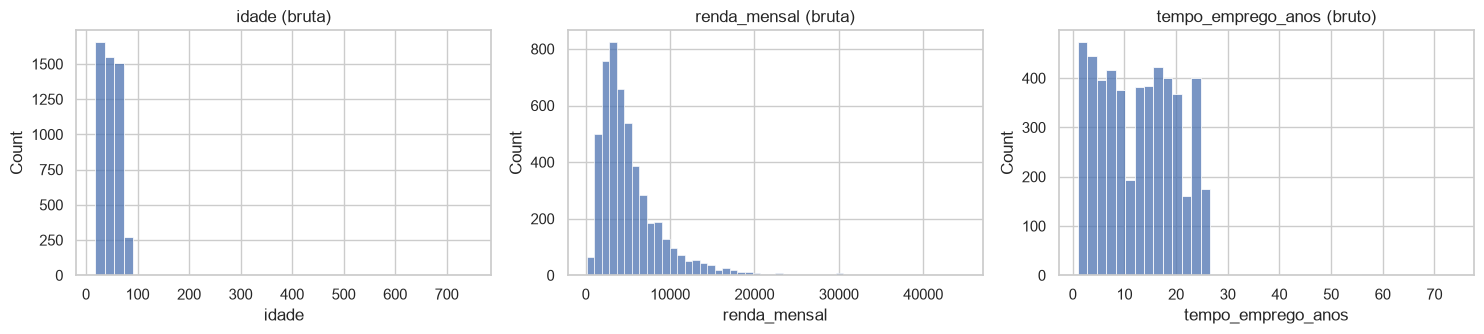

idade > 100: [210, 280, 300, 340, 360, 430, 440, 500, 540, 660, 670, 680, 700, 710, 750]
tempo_emprego > idade: 8 linhas
renda < 600: [100.0, 150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0, 500.0, 550.0]


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(data["idade"], bins=40, ax=ax[0]); ax[0].set_title("idade (bruta)")
sns.histplot(data["renda_mensal"], bins=50, ax=ax[1]); ax[1].set_title("renda_mensal (bruta)")
sns.histplot(data["tempo_emprego_anos"], bins=40, ax=ax[2]); ax[2].set_title("tempo_emprego_anos (bruto)")
plt.tight_layout(); plt.show()

print("idade > 100:", sorted(data.loc[data["idade"] > 100, "idade"].tolist()))
print("tempo_emprego > idade:", (data["tempo_emprego_anos"] > data["idade"]).sum(), "linhas")
print("renda < 600:", sorted(data.loc[data["renda_mensal"] < 600, "renda_mensal"].tolist()))

**Observações:**
- `estado` tem espaços sobrando em quantidades variadas (por exemplo `'  AC '`), o que gera **85 valores distintos** para apenas 27 UFs.
- `idade` tem valores extremos não condizentes a idades humanas. Os 15 valores acima de 100 (660, 680, 710, ...). *Possível erro de digitação.
- `tempo_emprego_anos` maior que a idade.
- `renda_mensal` tem poucos valores muito baixos (R$ 100 a R$ 550, de 50 em 50), que destoam do restante.
- Há linhas duplicadas.

## 2.3 Distribuição da variável resposta

,qtd,proporção
inadimplente,,
0,3280,0.66
1,1720,0.34


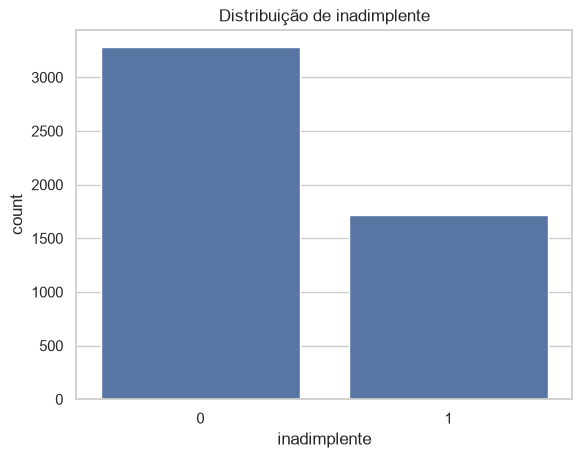

In [17]:
cont = data["inadimplente"].value_counts()
prop = data["inadimplente"].value_counts(normalize=True).round(3)
display(pd.DataFrame({"qtd": cont, "proporção": round(prop, 2)}))
ax = sns.countplot(x="inadimplente", data=data); ax.set_title("Distribuição de inadimplente")
plt.show()

Observações:

- Aproximadamente **34%** das propostas são inadimplentes. 

O desbalanceamento é **moderado**: a classe positiva é minoritária.

## 2.4 Outliers por classe (dados brutos)

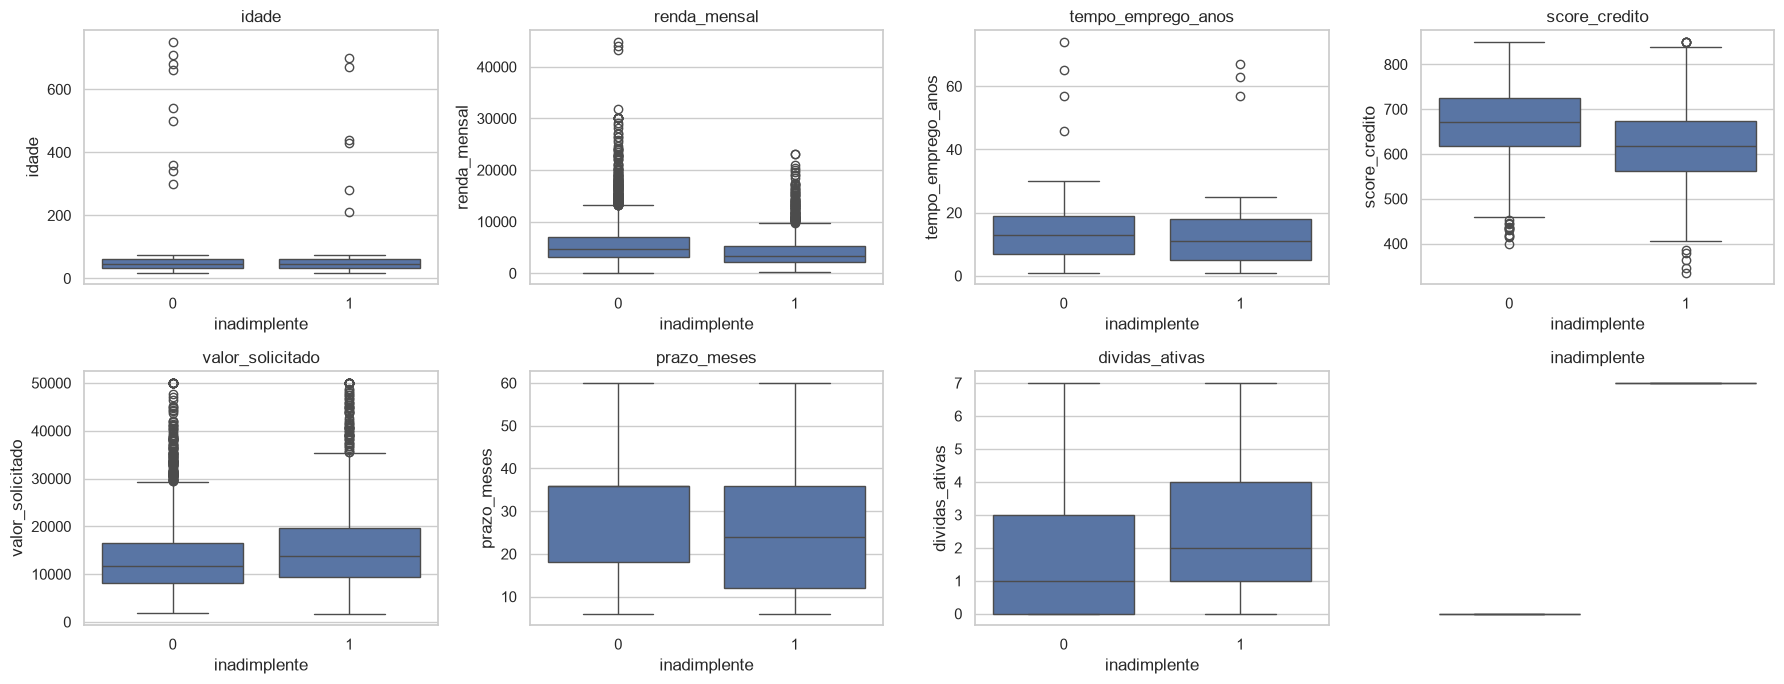

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_columns):
    sns.boxplot(x="inadimplente", y=c, data=data, ax=ax); ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

# 3. Limpeza e preparação dos dados

| Problema | Tratamento | Justificativa |
|---|---|---|
| `estado` com espaços e caixa variados (85 valores para 27 UFs) | `strip()` + `upper()` | Mesmo estado escrito de formas diferentes não pode virar categorias distintas |
| Linhas duplicadas | `drop_duplicates()` **depois** de padronizar o texto | Duplicatas só aparecem depois da padronização; evitam contar a mesma proposta duas vezes e vazar linhas iguais entre treino e teste |
| `idade` > 100 (ex.: 660 a 750) | vira `NaN` | Valores impossíveis, provável erro de digitação. Não dá para "adivinhar" a idade correta |
| `tempo_emprego_anos` ≥ `idade − 14` | vira `NaN` | **Premissa assumida:** ninguém trabalha antes dos 14 anos. A regra atinge uma parcela grande da base, então seu efeito é conferido adiante |
| `renda_mensal` < R$ 600 | vira `NaN` | Valores de R$ 100 a R$ 550, de 50 em 50, destoam do restante e estão muito abaixo do salário mínimo. **Premissa assumida** |
| `NaN` gerados | linhas removidas (`dropna`) | Opção pela simplicidade: não inventar valores. O custo é perder parte das linhas, por isso verificamos se a remoção muda o perfil da base |

**Valores ausentes:** a base original não tem nulos. Os `NaN` tratados são criados pela própria limpeza, ao invalidar valores impossíveis.

In [19]:
df_limpo, df_marcado = limpar_dados_credito(data, retornar_marcado=True)

✔️ Duplicatas removidas: 19 linhas descartadas. Restam 4981.

 Inconsistências identificadas e transformadas em NaN:
   - Idade irreal: 15 registros
   - Tempo de emprego impossível: 760 registros
   - Renda muito baixa: 10 registros

✔️ Linhas com inconsistências removidas (dropna): 782 linhas descartadas.
 Base final limpa: 4199 linhas e 11 colunas.


### Verificação: a remoção das linhas distorce a base?

Compara as linhas **mantidas** com as **removidas**. Se a taxa de inadimplência e o perfil forem parecidos, a remoção não enviesa o alvo.

In [20]:
cols_chk = ["idade", "renda_mensal", "tempo_emprego_anos"]
removidas = df_marcado[cols_chk].isna().any(axis=1)
alvo = df_marcado["inadimplente"].astype(int)

display(df_marcado[cols_chk].isna().sum().to_frame("NaN criados pela limpeza"))

verificacao = pd.DataFrame({
    "linhas": [len(df_marcado), int((~removidas).sum()), int(removidas.sum())],
    "taxa_inadimplencia": [alvo.mean(), alvo[~removidas].mean(), alvo[removidas].mean()],
    "score_credito_medio": [df_marcado["score_credito"].mean(),
                            df_marcado.loc[~removidas, "score_credito"].mean(),
                            df_marcado.loc[removidas, "score_credito"].mean()],
}, index=["base completa (sem duplicatas)", "mantidas", "removidas"])
display(verificacao.round(3))
print(f"Percentual de linhas removidas: {removidas.mean():.1%}")

,NaN criados pela limpeza
idade,15
renda_mensal,10
tempo_emprego_anos,760


,linhas,taxa_inadimplencia,score_credito_medio
base completa (sem duplicatas),4981,0.344,652.461
mantidas,4199,0.347,652.531
removidas,782,0.332,652.086


Percentual de linhas removidas: 15.7%


### Tipos das variáveis

In [21]:
# Converte todas as colunas da lista de uma vez
df_limpo[cat_columns] = df_limpo[cat_columns].astype("category")
df_limpo["inadimplente"] = df_limpo["inadimplente"].astype(int)

# 2b. Análise exploratória (continuação): relações com a inadimplência

Feita **após a limpeza** (Seção 3), com os dados já consistentes. Completa a Seção 2 do README.

,correlação de Spearman com inadimplente
score_credito,-0.302
renda_mensal,-0.228
prazo_meses,-0.115
tempo_emprego_anos,-0.091
idade,-0.063
valor_solicitado,0.138
dividas_ativas,0.162


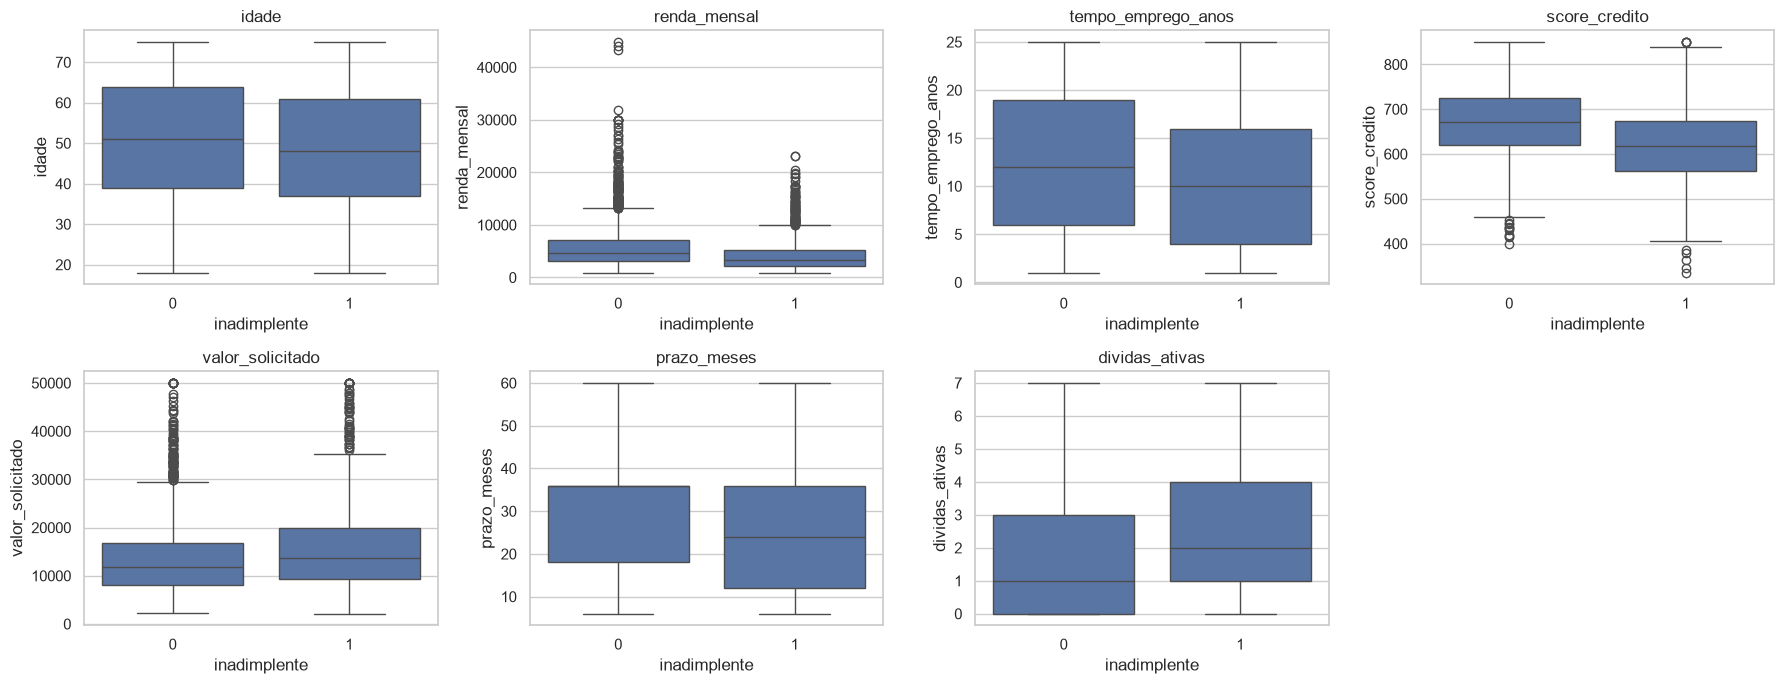

In [22]:
num_cols = ["idade", "renda_mensal", "tempo_emprego_anos", "score_credito", "valor_solicitado", "prazo_meses", "dividas_ativas"]
corr = df_limpo[num_cols + ["inadimplente"]].corr(method="spearman")["inadimplente"].drop("inadimplente").sort_values()
display(corr.round(3).to_frame("correlação de Spearman com inadimplente"))

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x="inadimplente", y=c, data=df_limpo, ax=ax); ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

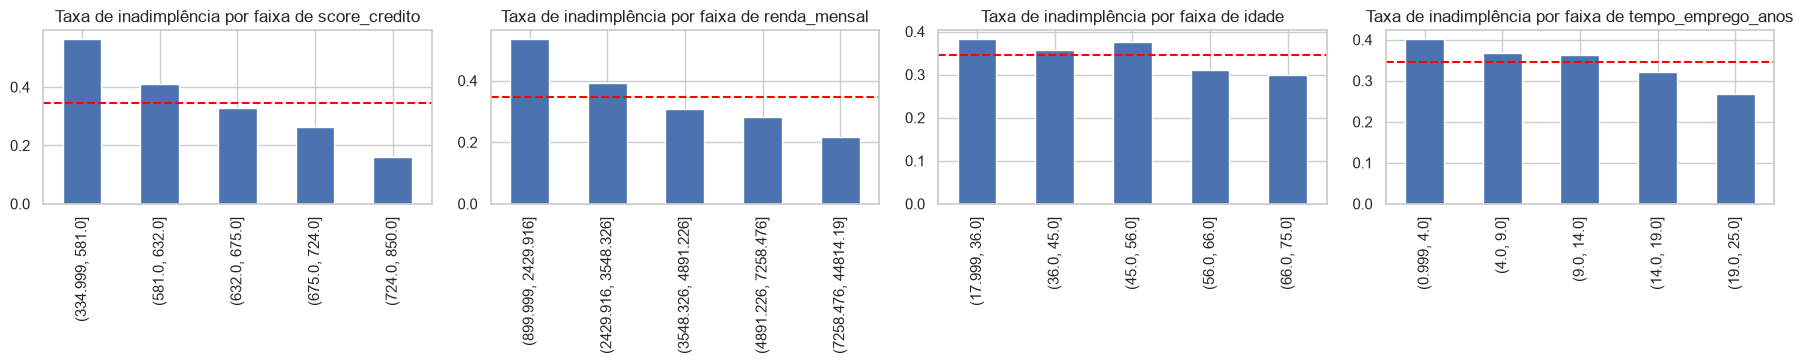

In [23]:
# Taxa de inadimplência por faixas (quintis) das variáveis numéricas contínuas
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, ["score_credito", "renda_mensal", "idade", "tempo_emprego_anos"]):
    t = df_limpo.groupby(pd.qcut(df_limpo[c], 5, duplicates="drop"))["inadimplente"].mean()
    t.plot(kind="bar", ax=ax); ax.set_title(f"Taxa de inadimplência por faixa de {c}")
    ax.set_xlabel(""); ax.axhline(df_limpo["inadimplente"].mean(), color="red", ls="--")
plt.tight_layout(); plt.show()

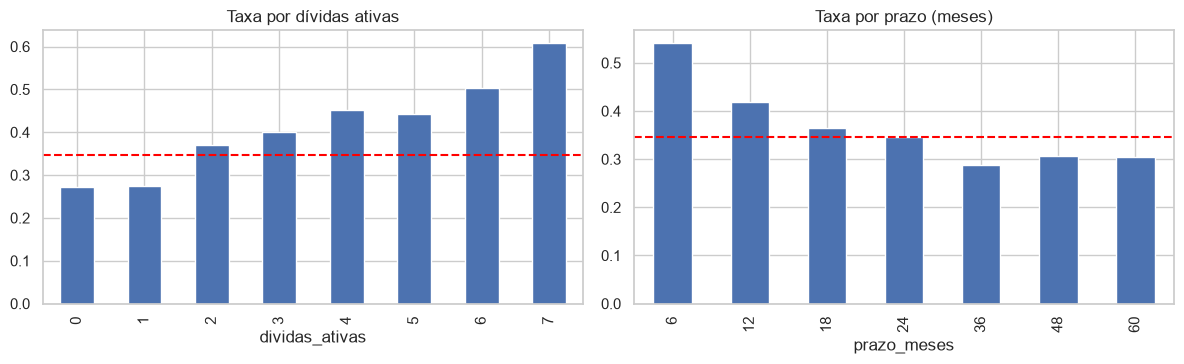

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
df_limpo.groupby("dividas_ativas")["inadimplente"].mean().plot(kind="bar", ax=axes[0], title="Taxa por dívidas ativas")
df_limpo.groupby("prazo_meses")["inadimplente"].mean().plot(kind="bar", ax=axes[1], title="Taxa por prazo (meses)")
for a in axes: a.axhline(df_limpo["inadimplente"].mean(), color="red", ls="--")
plt.tight_layout(); plt.show()

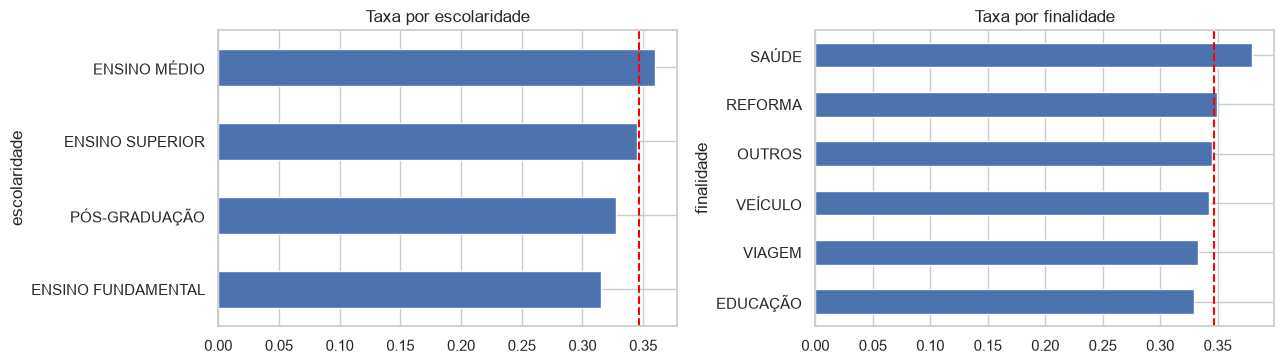

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, c in zip(axes, ["escolaridade", "finalidade"]):
    df_limpo.groupby(c, observed=True)["inadimplente"].mean().sort_values().plot(kind="barh", ax=ax, title=f"Taxa por {c}")
    ax.axvline(df_limpo["inadimplente"].mean(), color="red", ls="--")
plt.tight_layout(); plt.show()

**Observações:**
- `score_credito` é a variável numérica com a relação **mais forte**: quanto menor o score, maior a inadimplência.
- `renda_mensal` baixa e mais `dividas_ativas` também se associam a mais inadimplência.
- Prazos muito curtos (6 meses) mostram inadimplência alta. Isso é coerente com parcelas mais pesadas para o mesmo valor.
- `idade`, `escolaridade` e `finalidade` têm relação **fraca** com a variável alvo.

Isso sugere que o que importa é a **capacidade de pagamento** (renda frente ao tamanho da parcela). 

# 4. Engenharia de atributos

In [26]:
regioes = {
    "AC": "Norte", "AM": "Norte", "AP": "Norte", "PA": "Norte", "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
    "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MS": "Centro-Oeste", "MT": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}

df_limpo["regiao"] = df_limpo["estado"].astype(str).map(regioes)

assert df_limpo["regiao"].notna().all()

df_limpo["parcela_estimada"] = df_limpo["valor_solicitado"] / df_limpo["prazo_meses"]
df_limpo["comprometimento_renda"] = df_limpo["parcela_estimada"] / df_limpo["renda_mensal"]   # NaN se renda for NaN
df_limpo['renda_log'] = np.log1p(df_limpo['renda_mensal'])
df_limpo['faixa_idade'] = pd.qcut(df_limpo['idade'], q=5, labels=False)
df_limpo["estabilidade_emprego"] = df_limpo["tempo_emprego_anos"] / df_limpo["idade"]
df_limpo["score_por_idade"] = df_limpo["score_credito"] / df_limpo["idade"]
df_limpo['valor_solicitado_log'] = np.log1p(df_limpo['valor_solicitado'])
df_limpo["risco_renda_alta"] = (df_limpo["comprometimento_renda"] > 0.30).astype(int)

display(df_limpo[["valor_solicitado", "prazo_meses", "renda_mensal", "parcela_estimada", "comprometimento_renda"]].describe().T.round(3))
display(df_limpo.groupby("regiao")["inadimplente"].agg(["mean", "size"]).round(3))

,count,mean,std,min,25%,50%,75%,max
valor_solicitado,4199.0,14325.434,8270.998,2121.970,8494.595,12465.240,17859.970,50000.000
prazo_meses,4199.0,29.837,15.439,6.000,18.000,24.000,36.000,60.000
renda_mensal,4199.0,5250.916,4001.555,900.000,2704.045,4145.870,6473.730,44814.190
parcela_estimada,4199.0,688.479,694.779,49.767,273.996,462.867,833.126,8333.333
comprometimento_renda,4199.0,0.199,0.263,0.004,0.057,0.113,0.234,4.024


,mean,size
regiao,,
Centro-Oeste,0.356,649
Nordeste,0.348,1410
Norte,0.326,1045
Sudeste,0.341,624
Sul,0.382,471


Spearman com inadimplente:
score_credito           -0.302
renda_mensal            -0.228
prazo_meses             -0.115
valor_solicitado         0.138
parcela_estimada         0.180
comprometimento_renda    0.281
dtype: float64


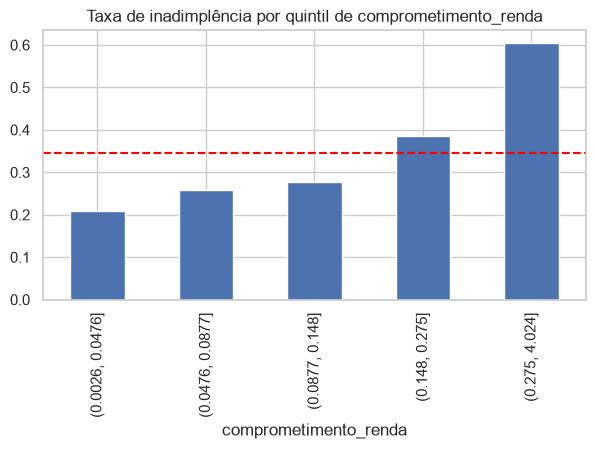

In [27]:
print("Spearman com inadimplente:")
print(df_limpo[["comprometimento_renda", "parcela_estimada", "renda_mensal", "valor_solicitado", "prazo_meses", "score_credito"]]
      .corrwith(df_limpo["inadimplente"], method="spearman").round(3).sort_values())

t = df_limpo.groupby(pd.qcut(df_limpo["comprometimento_renda"], 5))["inadimplente"].mean()
ax = t.plot(kind="bar", figsize=(7, 3.5), title="Taxa de inadimplência por quintil de comprometimento_renda")
ax.axhline(df_limpo["inadimplente"].mean(), color="red", ls="--"); plt.show()

### Explicação das variáveis derivadas

| Variável | Como foi construída | O que representa | Relação esperada com a inadimplência | Uso |
|---|---|---|---|---|
| `parcela_estimada` | `valor_solicitado / prazo_meses` | Valor aproximado da parcela mensal (**sem juros**, então subestima a parcela real) | Parcela maior pesa mais no orçamento → mais risco | Candidata na Seção 5 (descartada por redundância com `comprometimento_renda`) |
| **`comprometimento_renda`** | `parcela_estimada / renda_mensal` | **Fração da renda mensal consumida pela parcela**: capacidade de pagamento | Quanto maior, maior o risco. Combina três variáveis em uma só medida de esforço financeiro | **Candidata principal**; seu IV é calculado no treino (Seção 5.3) |
| `risco_renda_alta` | `1` se `comprometimento_renda > 0,30` | Indicador de endividamento excessivo (corte de 30% é uma regra de bolso do mercado, **arbitrária**) | Parcela acima de 30% da renda → mais risco | Descartada; redundante com `comprometimento_renda` |
| `regiao` | Mapeia a UF para a região do Brasil | Agrupa 27 estados em 5 categorias | Possível diferença regional de risco | Candidata categórica |
| `renda_log`, `valor_solicitado_log` | `log1p` da variável original | Reduz a assimetria de renda e valor | Mesma direção da variável original | Descartadas; mesma informação das originais |
| `faixa_idade`, `estabilidade_emprego`, `score_por_idade` | Quintis de idade; `tempo_emprego / idade`; `score / idade` | Faixa etária, proporção da vida no emprego atual e score relativo à idade | Mais estabilidade → menos risco | Descartadas; baixo poder preditivo e redundância |

**Hipótese central:** a inadimplência é mais explicada pela **capacidade de pagamento** (renda frente à parcela) do que por características demográficas, o que a análise exploratória já sugeria (`score_credito`, `renda_mensal` e `dividas_ativas` com as relações mais fortes; `idade`, `escolaridade` e `finalidade` com as mais fracas).

# 5. Preparação para modelagem

## 5.1 Variáveis candidatas e divisão treino/teste

**Variáveis candidatas.** Partimos das originais úteis e da derivada de maior sentido de negócio, e **retiramos versões redundantes** que carregam a mesma informação (`renda_log`, `valor_solicitado_log`, `parcela_estimada`, `risco_renda_alta`, `faixa_idade`, `score_por_idade`, `estabilidade_emprego`). Em uma regressão logística, variáveis muito correlacionadas deixam os coeficientes instáveis e difíceis de interpretar; conferimos isso com o **VIF**.

**Categóricas.** `escolaridade`, `finalidade` e `regiao` entram como candidatas e são codificadas com *one-hot* (interpretável na regressão). `estado` fica de fora: tem 27 categorias, `regiao` já resume a informação, e usar localização fina em decisão de crédito tem risco de discriminação.

**Transformações.** Numéricas padronizadas (`StandardScaler`). Tudo dentro de um `Pipeline`, então os parâmetros são aprendidos só no treino.

**Divisão.** 70% treino / 30% teste, estratificada pelo alvo, com semente fixa. **A divisão vem antes de qualquer decisão guiada pelo alvo.**

In [28]:
df_limpo.info()

<class 'pandas.DataFrame'>
RangeIndex: 4199 entries, 0 to 4198
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   idade                  4199 non-null   float64 
 1   estado                 4199 non-null   category
 2   escolaridade           4199 non-null   category
 3   renda_mensal           4199 non-null   float64 
 4   tempo_emprego_anos     4199 non-null   float64 
 5   score_credito          4199 non-null   int64   
 6   valor_solicitado       4199 non-null   float64 
 7   prazo_meses            4199 non-null   int64   
 8   finalidade             4199 non-null   category
 9   dividas_ativas         4199 non-null   int64   
 10  inadimplente           4199 non-null   int64   
 11  regiao                 4199 non-null   str     
 12  parcela_estimada       4199 non-null   float64 
 13  comprometimento_renda  4199 non-null   float64 
 14  renda_log              4199 non-null   float64 
 15

In [29]:
cols_num = df_limpo.select_dtypes(exclude=['category', 'object']).drop(columns=['inadimplente'], errors='ignore').columns.tolist()
cols_cat = df_limpo.select_dtypes(include=['category', 'object']).columns.tolist()
features = cols_num + cols_cat


X_all = df_limpo[features].copy()
y_all = df_limpo["inadimplente"].astype(int)

X_tr, X_te, y_tr, y_te = train_test_split(
    X_all, y_all, test_size=0.3, stratify=y_all, random_state=RANDOM_STATE
)

print(f"Treino: {X_tr.shape} | Teste: {X_te.shape}")
print(f"Taxa de inadimplência: treino {y_tr.mean():.3f} | teste {y_te.mean():.3f}")

Treino: (2939, 19) | Teste: (1260, 19)
Taxa de inadimplência: treino 0.346 | teste 0.347


## 5.2 Colinearidade entre as candidatas numéricas

In [30]:
display(calcular_vif(X_tr[cols_num]).to_frame("VIF"))

,VIF
idade,46.94
faixa_idade,24.71
tempo_emprego_anos,15.49
estabilidade_emprego,15.05
score_por_idade,10.15
valor_solicitado,8.83
renda_log,8.11
valor_solicitado_log,8.02
renda_mensal,5.78
parcela_estimada,5.20


## 5.3 Seleção de variáveis

Usamos dois critérios complementares:
- **IV (Information Value)**: poder de separação entre bons e maus pagadores, calculado para numéricas e categóricas (≥ 0,02 = poder mínimo; abaixo disso a variável quase não separa as classes);
- **Boruta** (numéricas): compara cada variável com versões embaralhadas dela mesma para decidir se tem sinal real.

Regra: numérica entra se for **confirmada** no Boruta e tiver IV ≥ 0,02, ou se for **tentativa** no Boruta e tiver IV ≥ 0,05. Categórica entra se tiver IV ≥ 0,02.

In [ ]:
# IV calculado SOMENTE no treino
treino_com_alvo = pd.concat([X_tr, y_tr], axis=1)
iv_tr = {}
for col in cols_num + cols_cat:
    iv_tr[col], _ = calcular_iv_woe(treino_com_alvo, col, "inadimplente")

# Boruta SOMENTE no treino (variáveis numéricas)
rf_sel = RandomForestClassifier(n_jobs=-1, class_weight="balanced", max_depth=5, random_state=RANDOM_STATE)
boruta_tr = BorutaPy(rf_sel, n_estimators="auto", random_state=RANDOM_STATE, verbose=0, max_iter=100)
boruta_tr.fit(X_tr[cols_num].values, y_tr.values)

status_boruta = {}
for c, ok, fraca in zip(cols_num, boruta_tr.support_, boruta_tr.support_weak_):
    status_boruta[c] = "confirmada" if ok else ("tentativa" if fraca else "rejeitada")

IV_MIN, IV_TENTATIVA = 0.02, 0.05
sel_num = [c for c in cols_num
           if (status_boruta[c] == "confirmada" and iv_tr[c] >= IV_MIN)
           or (status_boruta[c] == "tentativa" and iv_tr[c] >= IV_TENTATIVA)]
sel_cat = [c for c in cols_cat if iv_tr[c] >= IV_MIN]
assert sel_num, "Nenhuma variável numérica foi selecionada"

df_sel_tr = pd.DataFrame({"IV (treino)": pd.Series(iv_tr).round(4)})
df_sel_tr["tipo"] = ["numérica" if c in cols_num else "categórica" for c in df_sel_tr.index]
df_sel_tr["Boruta"] = pd.Series(status_boruta).reindex(df_sel_tr.index).fillna("n/a (só IV)")
df_sel_tr["selecionada"] = df_sel_tr.index.isin(sel_num + sel_cat)
display(df_sel_tr.sort_values("IV (treino)", ascending=False))

print("Numéricas selecionadas :", sel_num)
print("Categóricas selecionadas:", sel_cat if sel_cat else "nenhuma (IV abaixo do mínimo)")

# 6. Modelagem: Regressão Logística

- **Variáveis:** as selecionadas na Seção 5.3 (numéricas padronizadas + categóricas em *one-hot*).
- **Treinamento:** busca em grade sobre `C` (força da regularização) e `penalty` (L1 ou L2) com **validação cruzada estratificada de 5 folds no treino**, otimizando a **PR AUC** (`average_precision`), mais adequada que a acurácia para a classe minoritária.
- `class_weight='balanced'` compensa o desbalanceamento. Efeito colateral: as probabilidades ficam **superestimadas** (não calibradas), o que é conferido na Seção 7.4.

In [ ]:
pre_final = ColumnTransformer([
    ("num", StandardScaler(), sel_num),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), sel_cat),
])

pipe_final = Pipeline([
    ("prep", pre_final),
    ("modelo", LogisticRegression(class_weight="balanced", solver="saga",
                                  max_iter=5000, random_state=RANDOM_STATE)),
])

grid_final = {"modelo__C": [0.001, 0.01, 0.1, 1, 10, 50], "modelo__penalty": ["l1", "l2"]}
cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

busca_final = GridSearchCV(pipe_final, grid_final, scoring="average_precision", cv=cv_final, n_jobs=-1)
busca_final.fit(X_tr, y_tr)
modelo_final = busca_final.best_estimator_

print("Melhores parâmetros:", busca_final.best_params_)
print(f"PR AUC média na validação cruzada (treino): {busca_final.best_score_:.4f}")
print("Variáveis no modelo:", list(modelo_final.named_steps["prep"].get_feature_names_out()))

/Volumes/SSD_CAIO/FasTrackAI-Compass/fast-track-ia-t1/desafios/analise-credito/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Volumes/SSD_CAIO/FasTrackAI-Compass/fast-track-ia-t1/desafios/analise-credito/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Volumes/SSD_CAIO/FasTrackAI-Compass/fast-track-ia-t1/desafios/analise-credito/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Volumes/SSD_CAIO/FasTrackAI-Compass/fast-track-ia-t1/desafios/analise-credito/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:

Melhores parâmetros: {'modelo__C': 0.1, 'modelo__penalty': 'l1'}
PR AUC média na validação cruzada (treino): 0.6895
Variáveis no modelo: ['num__idade', 'num__renda_mensal', 'num__tempo_emprego_anos', 'num__score_credito', 'num__valor_solicitado', 'num__dividas_ativas', 'num__parcela_estimada', 'num__comprometimento_renda', 'num__renda_log', 'num__estabilidade_emprego', 'num__score_por_idade', 'num__valor_solicitado_log', 'num__risco_renda_alta', 'cat__estado_AL', 'cat__estado_AM', 'cat__estado_AP', 'cat__estado_BA', 'cat__estado_CE', 'cat__estado_DF', 'cat__estado_ES', 'cat__estado_GO', 'cat__estado_MA', 'cat__estado_MG', 'cat__estado_MS', 'cat__estado_MT', 'cat__estado_PA', 'cat__estado_PB', 'cat__estado_PE', 'cat__estado_PI', 'cat__estado_PR', 'cat__estado_RJ', 'cat__estado_RN', 'cat__estado_RO', 'cat__estado_RR', 'cat__estado_RS', 'cat__estado_SC', 'cat__estado_SE', 'cat__estado_SP', 'cat__estado_TO']


/Volumes/SSD_CAIO/FasTrackAI-Compass/fast-track-ia-t1/desafios/analise-credito/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


# 7. Avaliação e interpretação

Todas as avaliações usam o **conjunto de teste**, que não participou do treino nem da seleção de variáveis.

## 7.1 Métricas e comparação com referências simples

Um modelo só é útil se superar alternativas triviais. Comparamos, no **teste**, com:
- **Dummy (prior):** prevê sempre a classe majoritária (aprovar todo mundo). Mostra o que a acurácia "de graça" entrega;
- **Dummy (estratificado):** sorteia previsões respeitando a proporção das classes (equivalente a chutar);
- **Regra simples:** "negar se o `score_credito` for menor que a mediana do treino", algo que um analista faria sem modelo.

In [ ]:
dummy_prior = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
dummy_estrat = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(X_tr, y_tr)

mediana_score = X_tr["score_credito"].median()
pred_regra = (X_te["score_credito"] < mediana_score).astype(int)

linhas = [
    avaliar_modelo(dummy_prior, X_te, y_te, "Dummy (sempre aprovar)"),
    avaliar_modelo(dummy_estrat, X_te, y_te, "Dummy (estratificado)"),
    metricas_de_predicoes(y_te, pred_regra, -X_te["score_credito"], "Regra: score < mediana"),
    avaliar_modelo(modelo_final, X_te, y_te, "Regressão Logística (final)"),
]

df_comp = pd.DataFrame(linhas).set_index("Modelo")
display(df_comp.round(4))
print(f"Referência da PR AUC ao acaso = taxa de inadimplentes no teste = {y_te.mean():.3f}")

,Acurácia,Acurácia Balanceada,G-Mean,ROC AUC,PR AUC,F1 Score,Recall,Precision,MCC
Modelo,,,,,,,,,
Dummy (sempre aprovar),0.6532,0.5000,0.0000,0.5000,0.3468,0.0000,0.0000,0.0000,0.0000
Dummy (estratificado),0.5357,0.4863,0.4587,0.4863,0.3409,0.3268,0.3249,0.3287,-0.0275
Regra: score < mediana,0.6333,0.6539,0.6504,0.6977,0.5194,0.5769,0.7208,0.4809,0.2931
Regressão Logística (final),0.7262,0.7233,0.7233,0.8001,0.6840,0.6440,0.7140,0.5865,0.4304


Referência da PR AUC ao acaso = taxa de inadimplentes no teste = 0.347


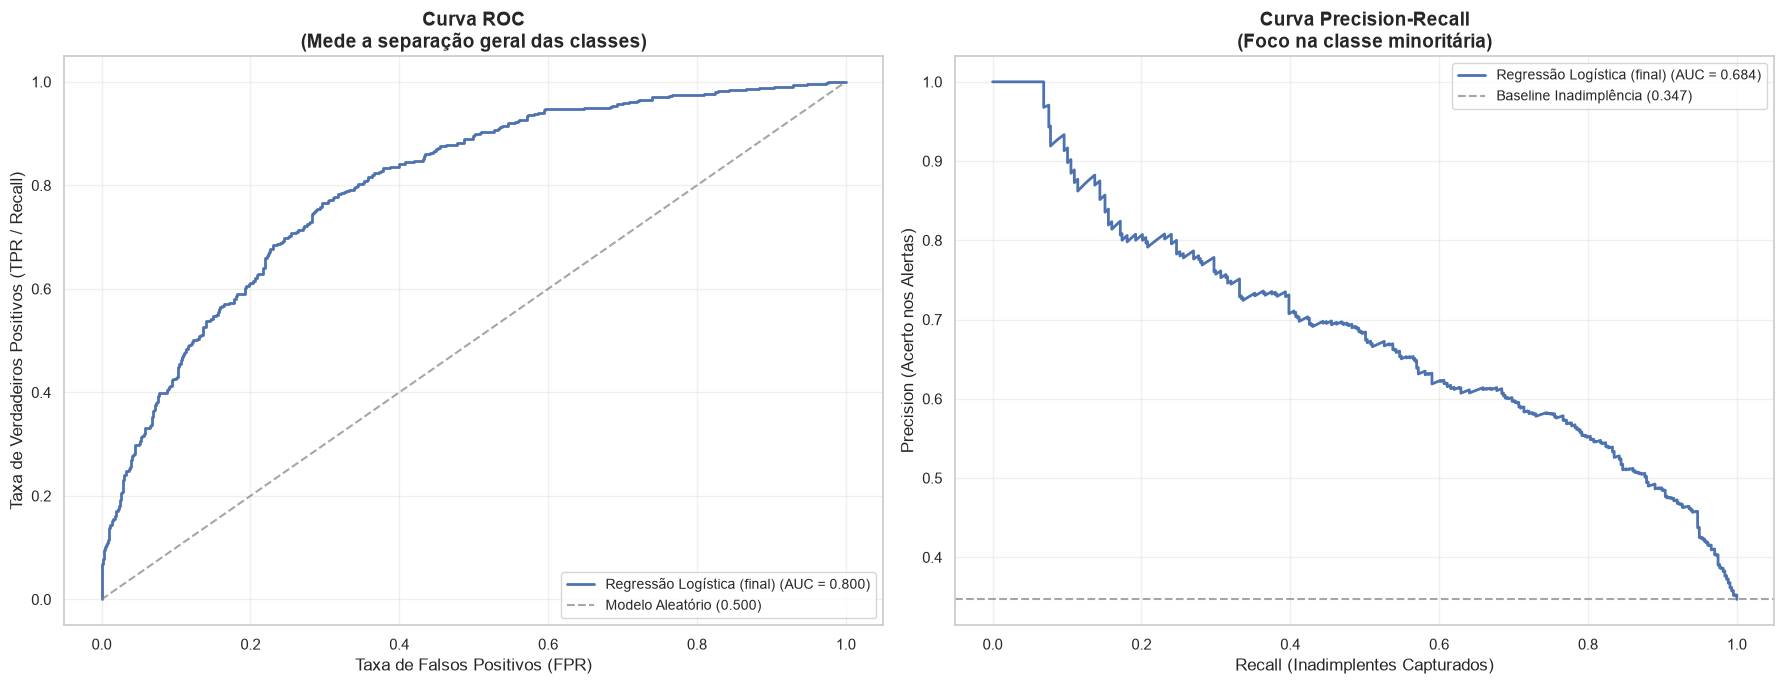

In [ ]:
plotar_curvas_roc_pr(modelo_final, X_te, y_te, "Regressão Logística (final)")

## 7.2 Quais variáveis mais se relacionam com o resultado previsto

Os coeficientes da regressão logística (numéricas já padronizadas) mostram o efeito de cada variável no **log da chance** de inadimplência:
- coeficiente **positivo** → aumenta o risco; **negativo** → reduz;
- `odds_ratio = exp(coeficiente)`: para numéricas, é a variação multiplicativa na chance de inadimplência a cada **1 desvio-padrão** a mais na variável; para categóricas, é a comparação com a categoria de referência;
- como as numéricas estão na mesma escala, o **valor absoluto** do coeficiente permite comparar a força relativa.

Cuidado: o resultado descreve **associação**, não causa.

,variavel,coeficiente,odds_ratio,|coef|
0,score_credito,-0.7696,0.4632,0.7696
1,comprometimento_renda,0.6607,1.9362,0.6607
2,dividas_ativas,0.4197,1.5215,0.4197
3,renda_log,-0.2607,0.7705,0.2607
4,tempo_emprego_anos,-0.2539,0.7757,0.2539
5,idade,-0.1373,0.8717,0.1373
6,risco_renda_alta,0.0917,1.0961,0.0917
7,valor_solicitado_log,0.0912,1.0955,0.0912
8,score_por_idade,-0.0868,0.9169,0.0868
9,parcela_estimada,-0.0334,0.9671,0.0334


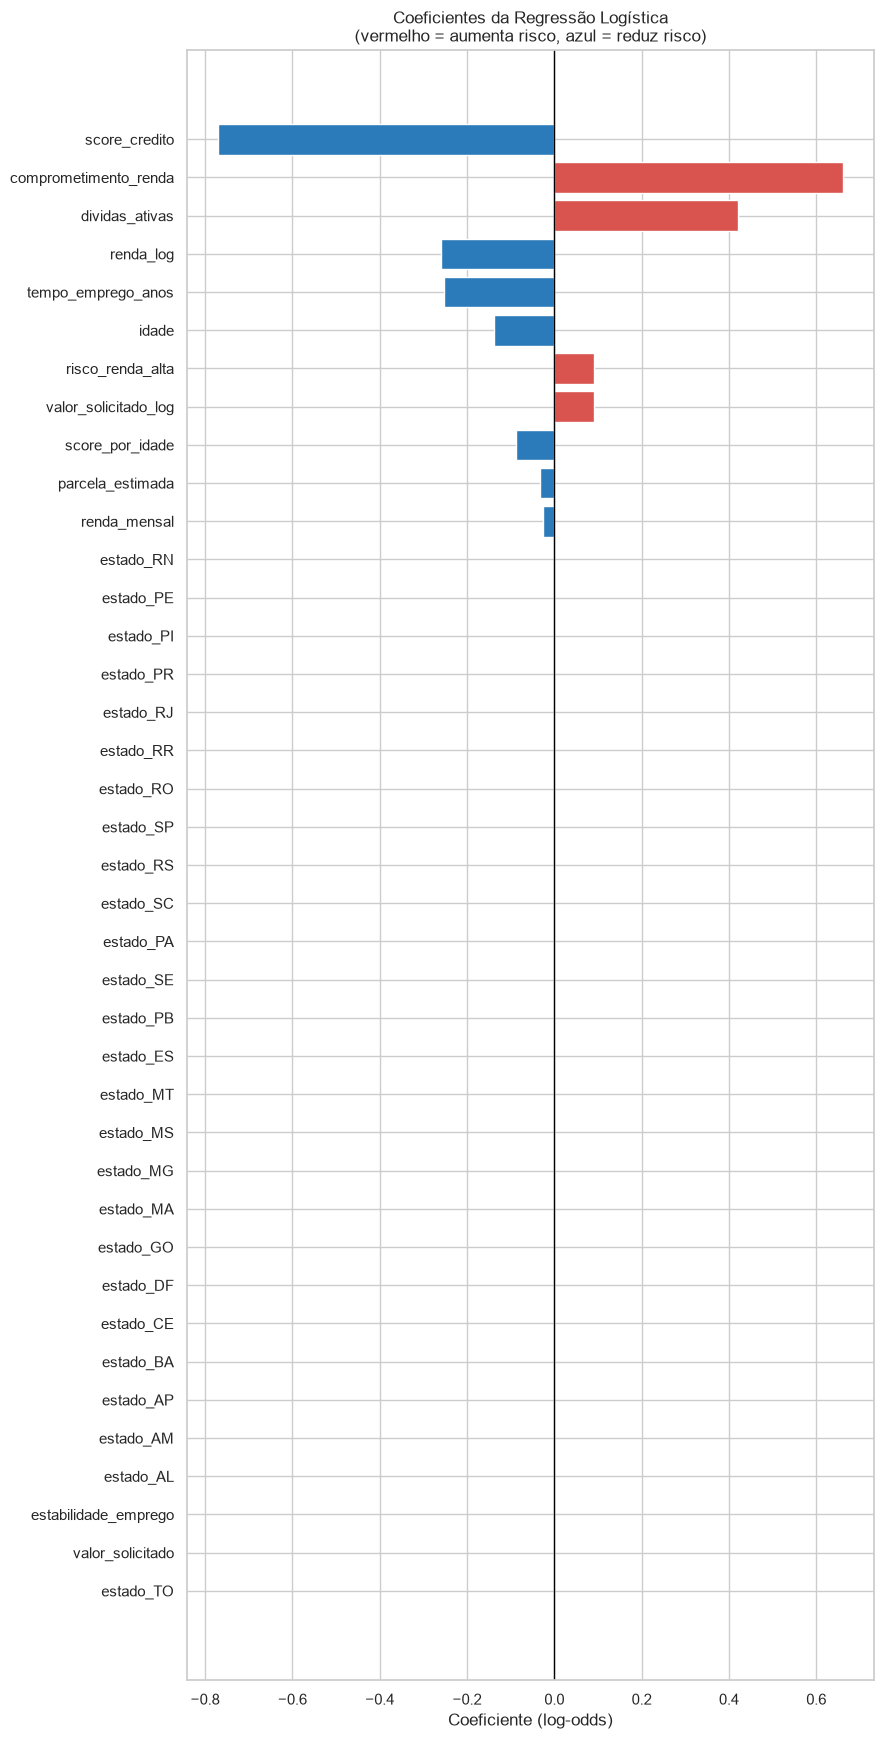

• score_credito: reduz o risco (odds ratio = 0.46)
• comprometimento_renda: aumenta o risco (odds ratio = 1.94)
• dividas_ativas: aumenta o risco (odds ratio = 1.52)


In [ ]:
nomes = [n.split("__", 1)[1] for n in modelo_final.named_steps["prep"].get_feature_names_out()]
coefs = modelo_final.named_steps["modelo"].coef_[0]

df_coef = pd.DataFrame({"variavel": nomes, "coeficiente": coefs, "odds_ratio": np.exp(coefs)})
df_coef["|coef|"] = df_coef["coeficiente"].abs()
df_coef = df_coef.sort_values("|coef|", ascending=False).reset_index(drop=True)
display(df_coef.round(4))

plt.figure(figsize=(9, max(3, 0.45 * len(df_coef))))
cores = ["#d9534f" if v > 0 else "#2b7bba" for v in df_coef["coeficiente"]]
plt.barh(df_coef["variavel"][::-1], df_coef["coeficiente"][::-1], color=cores[::-1])
plt.axvline(0, color="black", lw=1)
plt.title("Coeficientes da Regressão Logística\n(vermelho = aumenta risco, azul = reduz risco)")
plt.xlabel("Coeficiente (log-odds)")
plt.tight_layout()
plt.show()

for _, r in df_coef.head(3).iterrows():
    sentido = "aumenta" if r["coeficiente"] > 0 else "reduz"
    print(f"• {r['variavel']}: {sentido} o risco (odds ratio = {r['odds_ratio']:.2f})")

## 7.3 Ponto de corte e valor para o negócio

O modelo devolve probabilidades; **decidir aprovar ou negar exige um ponto de corte**, e a escolha depende dos custos. Usamos valores **hipotéticos** (a CredAIR não informou custos): cada bom pagador aprovado gera **R$ 800** e cada inadimplente aprovado custa **R$ 4.000**. Para não usar o teste na escolha, o corte é definido com **predições out-of-fold no treino** e só então aplicado ao teste, uma vez.

/Volumes/SSD_CAIO/FasTrackAI-Compass/fast-track-ia-t1/desafios/analise-credito/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Volumes/SSD_CAIO/FasTrackAI-Compass/fast-track-ia-t1/desafios/analise-credito/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Volumes/SSD_CAIO/FasTrackAI-Compass/fast-track-ia-t1/desafios/analise-credito/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Volumes/SSD_CAIO/FasTrackAI-Compass/fast-track-ia-t1/desafios/analise-credito/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:

=== Otimização Matemática (Máximo F1-Score) ===
Threshold Ideal: 0.45
F1-Score: 0.6347
Lucro Projetado: R$ 59,200.00

=== Otimização de Negócio (Máximo Lucro) ===
Threshold Ideal: 0.24
Lucro Projetado: R$ 262,400.00
Clientes Aprovados: 616
Inadimplência da Carteira: 7.79%


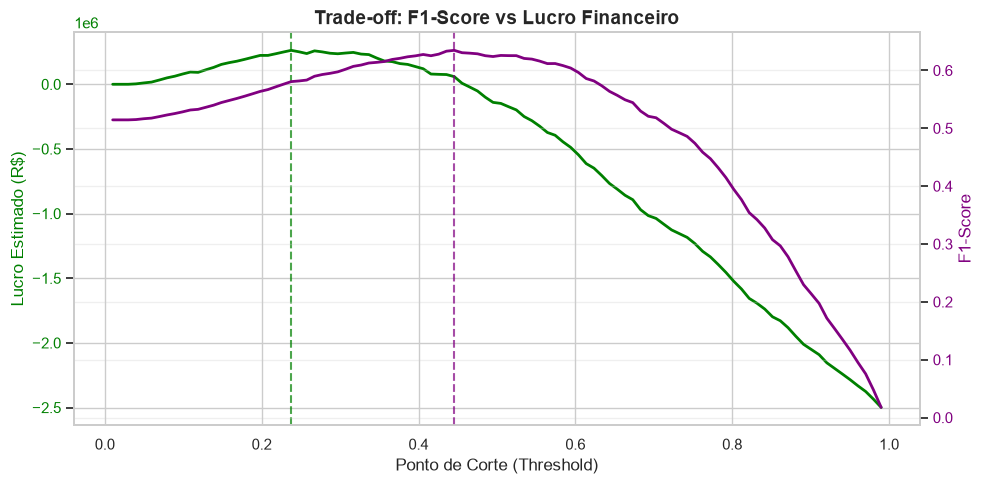

,Corte,Aprovados,Inadimplência dos aprovados,Lucro (R$)
Cenário,,,,
Aprovar todos (sem modelo),1.01,1260,0.347,-1089600
"Corte padrão 0,50",0.50,728,0.172,-17600
Corte ótimo (escolhido no treino),0.24,275,0.073,124000


In [ ]:
LUCRO_BOM, CUSTO_CALOTE = 800, 4000   # PREMISSAS HIPOTÉTICAS (não são dados da CredAIR)

# Probabilidades out-of-fold no treino (cada linha prevista por um modelo que não a viu)
proba_oof = cross_val_predict(modelo_final, X_tr, y_tr, cv=cv_final, method="predict_proba")[:, 1]
df_thr_oof, thr_oof = otimizar_threshold(y_tr, proba_oof, LUCRO_BOM, CUSTO_CALOTE)

# Aplicação ÚNICA no teste
proba_te = modelo_final.predict_proba(X_te)[:, 1]

def cenario_lucro(nome, corte):
    pred = (proba_te >= corte).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
    aprovados = tn + fn
    return {"Cenário": nome, "Corte": round(float(corte), 2), "Aprovados": int(aprovados),
            "Inadimplência dos aprovados": (fn / aprovados) if aprovados else np.nan,
            "Lucro (R$)": tn * LUCRO_BOM - fn * CUSTO_CALOTE}

resumo_lucro = pd.DataFrame([
    cenario_lucro("Aprovar todos (sem modelo)", 1.01),
    cenario_lucro("Corte padrão 0,50", 0.5),
    cenario_lucro("Corte ótimo (escolhido no treino)", thr_oof),
]).set_index("Cenário")
display(resumo_lucro.round(3))

## 7.4 Separação entre bons e maus pagadores (decis e KS) e calibração

Tabela de decis com o **Decil 1 = maior risco** (10% das propostas com maior probabilidade prevista). Um bom modelo concentra a inadimplência nos primeiros decis, com a taxa caindo de forma consistente até o Decil 10. O **KS** resume a separação máxima entre as distribuições acumuladas de maus e bons pagadores.

,total,maus,prob_min,prob_max,bons,taxa_inadimplencia,%_maus_capturados,%_maus_acumulado,%_bons_acumulado
decil,,,,,,,,,
1,126,101,0.818,1.000,25,0.802,0.231,0.231,0.030
2,126,77,0.698,0.817,49,0.611,0.176,0.407,0.090
3,126,69,0.592,0.697,57,0.548,0.158,0.565,0.159
4,126,56,0.519,0.592,70,0.444,0.128,0.693,0.244
5,126,45,0.440,0.518,81,0.357,0.103,0.796,0.343
6,126,34,0.368,0.438,92,0.270,0.078,0.874,0.454
7,126,27,0.293,0.368,99,0.214,0.062,0.936,0.575
8,126,11,0.222,0.292,115,0.087,0.025,0.961,0.714
9,126,10,0.147,0.222,116,0.079,0.023,0.984,0.855


KS no teste: 45.37%


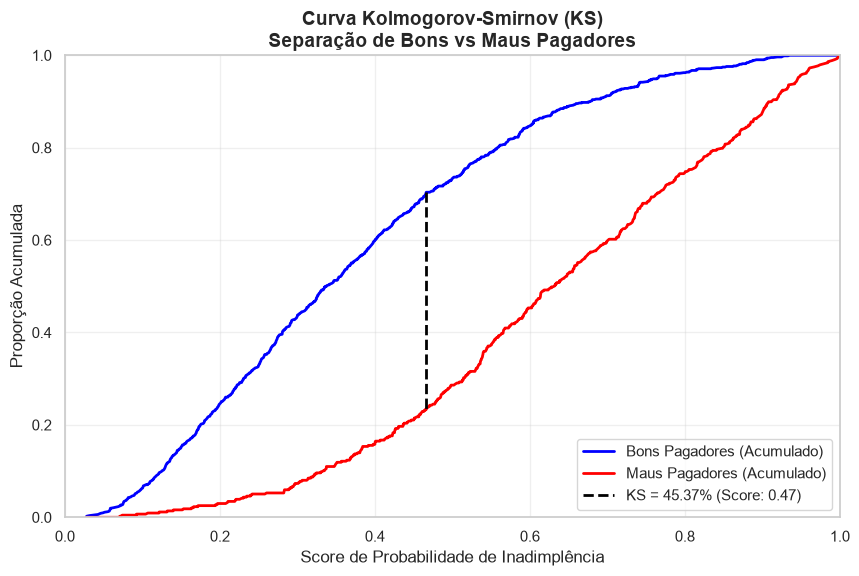

In [ ]:
tab_decis, ks_te = tabela_decis_risco(y_te, proba_te)
display(tab_decis.round(3))
print(f"KS no teste: {ks_te:.2f}%")

plotar_curva_ks(pd.DataFrame({"target": y_te.values, "proba": proba_te}), ks_te)

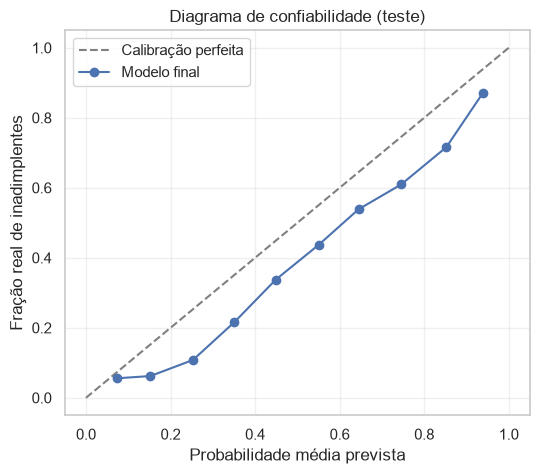

Probabilidade média prevista: 0.461 | taxa real no teste: 0.347
Se a média prevista for bem maior que a taxa real, as probabilidades estão superestimadas (efeito do class_weight='balanced').


In [ ]:
# Diagnóstico de calibração no teste (apenas observação, nada é ajustado aqui)
prob_real, prob_prev = calibration_curve(y_te, proba_te, n_bins=10)
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Calibração perfeita")
plt.plot(prob_prev, prob_real, marker="o", label="Modelo final")
plt.xlabel("Probabilidade média prevista"); plt.ylabel("Fração real de inadimplentes")
plt.title("Diagrama de confiabilidade (teste)"); plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"Probabilidade média prevista: {proba_te.mean():.3f} | taxa real no teste: {y_te.mean():.3f}")

# 8. Conclusão

**Principais padrões encontrados nos dados**
- Cerca de **34%** das propostas são inadimplentes (desbalanceamento moderado).
- Os dados brutos tinham problemas de qualidade: estado com espaços e caixa variados, idades impossíveis, tempo de emprego maior que a idade, rendas muito baixas e linhas duplicadas. Após a limpeza, a base ficou com 4.199 das 5.000 linhas originais.
- A inadimplência está mais ligada à **capacidade de pagamento** do que ao perfil demográfico.

**Principais fatores relacionados à inadimplência**
- `score_credito` é a variável numérica com relação mais forte: menor score, mais inadimplência.
- `comprometimento_renda` (parcela estimada ÷ renda), a variável derivada criada, está entre as de maior poder de separação (IV no treino, Seção 5.3).
- `renda_mensal` baixa e mais `dividas_ativas` também se associam a mais risco; `valor_solicitado` tem associação positiva, mais modesta.
- `idade`, `escolaridade` e `finalidade` têm relação fraca.
- A tabela de coeficientes da Seção 7.2 mostra o peso relativo de cada variável no modelo final.

**Resultados do modelo**
- A Regressão Logística foi comparada, no teste, com baselines (sempre aprovar, chute estratificado e regra por score). A célula de resumo ao final traz os números desta execução, e a Seção 7.1 a tabela completa.
- O teste não participou de nenhuma decisão (seleção de variáveis, hiperparâmetros e ponto de corte usam só o treino), então as métricas refletem desempenho em dados novos da mesma distribuição.

**Limitações da análise**
- **Dados sintéticos**: os resultados valem para o exercício, não para uma carteira real.
- **Divisão aleatória**, sem dimensão temporal: em produção seria necessária validação *out-of-time*.
- **Viés de seleção**: só temos o desfecho de propostas que foram aprovadas e acompanhadas; não sabemos como as recusadas teriam se comportado.
- A limpeza usou **premissas** (trabalho a partir dos 14 anos, renda mínima de R$ 600) e removeu parte relevante das linhas; a verificação da Seção 3 indica se isso alterou o perfil da base.
- `parcela_estimada` ignora juros; os valores de lucro e custo são **hipotéticos**; `class_weight='balanced'` deixa as probabilidades superestimadas.
- A regressão logística assume relações lineares no log-odds e não captura interações automaticamente.

**Cuidados para uso em situação real**
- Validar em dados mais recentes que o treino e **monitorar deriva** (PSI) das variáveis e do desempenho; recalibrar quando necessário.
- Definir o ponto de corte com **custos reais** da operação e com revisão humana para casos de fronteira.
- Auditar **justiça e discriminação** (localização, idade e escolaridade como possíveis proxies de atributos protegidos) e garantir **explicabilidade** ao cliente, conforme a LGPD e a regulação de crédito.
- Tratar o modelo como **apoio à decisão**, não como decisor único, e manter um modelo desafiante para comparação.

In [ ]:
# Resumo numérico desta execução (preenchido automaticamente)
f = df_comp.loc["Regressão Logística (final)"]
d = df_comp.loc["Dummy (sempre aprovar)"]
r = df_comp.loc["Regra: score < mediana"]

print(f"Base: {len(df_limpo)} linhas após a limpeza | inadimplência: {y_all.mean():.1%}")
print(f"Variáveis do modelo: {sel_num + sel_cat}")
print(f"Parâmetros: {busca_final.best_params_}")
print()
print(f"ROC AUC — modelo {f['ROC AUC']:.3f} | regra por score {r['ROC AUC']:.3f} | dummy {d['ROC AUC']:.3f}")
print(f"PR AUC  — modelo {f['PR AUC']:.3f} | regra por score {r['PR AUC']:.3f} | acaso {y_te.mean():.3f}")
print(f"Recall {f['Recall']:.3f} | Precision {f['Precision']:.3f} | F1 {f['F1 Score']:.3f} | MCC {f['MCC']:.3f} (corte 0,50)")
print(f"KS no teste: {ks_te:.1f}%")
print()
print("Maiores efeitos (coeficientes):")
for _, x in df_coef.head(3).iterrows():
    print(f"  {x['variavel']}: odds ratio {x['odds_ratio']:.2f} ({'↑ risco' if x['coeficiente'] > 0 else '↓ risco'})")
print()
display(resumo_lucro.round(3))

Base: 4199 linhas após a limpeza | inadimplência: 34.7%
Variáveis do modelo: ['idade', 'renda_mensal', 'tempo_emprego_anos', 'score_credito', 'valor_solicitado', 'dividas_ativas', 'parcela_estimada', 'comprometimento_renda', 'renda_log', 'estabilidade_emprego', 'score_por_idade', 'valor_solicitado_log', 'risco_renda_alta', 'estado']
Parâmetros: {'modelo__C': 0.1, 'modelo__penalty': 'l1'}

ROC AUC — modelo 0.800 | regra por score 0.698 | dummy 0.500
PR AUC  — modelo 0.684 | regra por score 0.519 | acaso 0.347
Recall 0.714 | Precision 0.586 | F1 0.644 | MCC 0.430 (corte 0,50)
KS no teste: 45.4%

Maiores efeitos (coeficientes):
  score_credito: odds ratio 0.46 (↓ risco)
  comprometimento_renda: odds ratio 1.94 (↑ risco)
  dividas_ativas: odds ratio 1.52 (↑ risco)



,Corte,Aprovados,Inadimplência dos aprovados,Lucro (R$)
Cenário,,,,
Aprovar todos (sem modelo),1.01,1260,0.347,-1089600
"Corte padrão 0,50",0.50,728,0.172,-17600
Corte ótimo (escolhido no treino),0.24,275,0.073,124000
